# Лабораторная работа 5
## Деревья решений


Министерство науки и высшего образования Российской Федерации

федеральное государственное автономное образовательное учреждение высшего образования

“НАЦИОНАЛЬНЫЙ ИССЛЕДОВАТЕЛЬСКИЙ УНИВЕРСИТЕТ ИТМО”

| Поле | Значение |
| --- | --- |
| Факультет | Программной Инженерии и Компьютерной Техники |
| Направление подготовки (специальность) | СППО |
| Дисциплина | Системы искусственного интеллекта |

Лабораторная работа 5

ОТЧЕТ 

| Поле | Значение |
| --- | --- |
| Выполнил студент: | Чжун Цзяцзюнь 407959 |
| Группа: | P3310 |
| Преподаватель: | Болдырева Елена Александровна (157150) |

г. Санкт-Петербург

2026

## ЦЕЛЬ РАБОТЫ И ТЕОРЕТИЧЕСКИЕ СВЕДЕНИЯ

Деревья решений. Вариант нечётный. 

Цель: самостоятельно реализовать многоветвевое дерево ID3 для бинарной классификации категориальных данных, оценить качество и переобучение, построить ROC- и PR-кривые и вычислить AUC методом трапеций.

В узле выбирается один из оставшихся признаков с максимальным информационным выигрышем. Для каждой категории создаётся своя ветвь. Энтропия измеряет неопределённость класса: для чистого узла она равна нулю, при равных долях двух классов достигает одного бита.

$$
H(S)=-\sum_{c\in\{0,1\}}p_c\log_2 p_c,\qquad 0\log_2 0=0
$$

$$
IG(S,A)=H(S)-\sum_{v\in V_A}\frac{|S_v|}{|S|}H(S_v)
$$

Рекурсия останавливается при чистом узле, отсутствии оставшихся признаков или неположительном максимальном IG. В вычислениях выигрыш не более 10⁻¹² считается нулём. При равных выигрышах сохраняется порядок признаков после случайного отбора. Один признак используется не более одного раза на каждом пути.

Каждый узел хранит число обучающих объектов n и долю p₁ объектов класса 1. Прогноз вероятности равен p₁ в достигнутом листе. Если категории нет среди ветвей, используется p₁ текущего узла. Класс равен 1 при p₁ ≥ t, иначе 0, основной порог t = 0,5.

$$
p_1=\frac{n_1}{n},\qquad \hat y(t)=\mathbf{1}[p_1\ge t]
$$

$$
\operatorname{Accuracy}=\frac{TP+TN}{N},\qquad \operatorname{Precision}=\frac{TP}{TP+FP}
$$

$$
\operatorname{Recall}=TPR=\frac{TP}{TP+FN},\qquad FPR=\frac{FP}{FP+TN}
$$

TP и TN — верные положительные и отрицательные прогнозы, FP и FN — ложноположительные и ложноотрицательные. При H₀: y=0 ошибки FP относятся к I роду, FN — ко II. При нулевом знаменателе precision или recall в таблицах принимается равным нулю.

ROC строится по FPR и TPR, PR — по recall и precision. Для площади координаты стабильно сортируются по x, затем суммируются площади трапеций. На ROC присутствуют точки (0, 0), (1, 1) и диагональ случайного классификатора.

$$
\operatorname{AUC}=\sum_{i=1}^{m-1}(x_{i+1}-x_i)\frac{y_{i+1}+y_i}{2}
$$

Алгоритм дерева, метрики, перебор порогов и интегрирование реализованы самостоятельно. NumPy используется для вычислений, Pandas — для таблиц, Matplotlib — для графиков, из sklearn вызывается только разрешённая функция train_test_split.

## ПОДГОТОВКА ДАННЫХ

Использован Higher Education Students Performance Evaluation, UCI № 856 [1]. Исходный CSV содержит 145 строк, ID студента, 31 предиктор и GRADE. Цель y = 1 при GRADE ≥ 3, иначе y = 0. GRADE и STUDENT ID исключены из признаков до отбора. COURSE ID — код курса, а не идентификатор студента, он остаётся допустимым категориальным предиктором.

Пропусков и полных дубликатов строк в исходном файле нет. Для потенциальных пропусков предусмотрена отдельная категория `<MISSING>`, включая символ ? и пустые строки. Строки не удаляются. Все коды трактуются как категории: нормализация, one-hot-кодирование и числовые пороги не применяются.

| Выборка | Класс 0 | Класс 1 | Всего |
| --- | --- | --- | --- |
| Все данные | 67 | 78 | 145 |
| Train | 54 | 62 | 116 |
| Test | 13 | 16 | 29 |

Разбиение train/test = 80/20 выполнено с stratify=y и random_state=42. Доля класса 1: 53,79 % в полном наборе, 53,45 % в train и 55,17 % в test. Небольшое отличие обусловлено целым числом объектов. Индексы строк сохранены в split.csv.

Из n = 31 признака один раз до построения дерева выбраны floor(√31) = 5. Использован отдельный генератор NumPy default_rng(42), choice без возвращения. Повторный отбор в узлах не выполняется. Названия в коде сопоставлены исходным столбцам:

| Столбец CSV | Имя в программе | Смысл и категории |
| --- | --- | --- |
| 22 | class_attendance | Посещение занятий: 1 всегда, 2 иногда, 3 никогда |
| 14 | parental_status | Статус родителей: 1 в браке, 2 разведены, 3 умер один или оба |
| 19 | reading_scientific | Чтение научных книг/журналов: 1 нет, 2 иногда, 3 часто |
| 3 | high_school_type | Школа: 1 частная, 2 государственная, 3 другая |
| COURSE ID | course_id | Категориальный код курса, наблюдаются значения 1–9 |

В данных встречаются только категории посещения 1 и 2, категория 3 указана в описании UCI. Ни качество на test, ни значения GRADE не используются для выбора пяти признаков. Тест служит оценке уже построенной модели, пороги ниже исследуются описательно, без подбора лучшего порога по тесту.

## СТРУКТУРА ПОСТРОЕННОГО ДЕРЕВА

Корень имеет глубину 0. Полная глубина равна 5, число листьев — 31, число всех узлов — 48. Внутренние узлы используют все пять отобранных признаков. Ниже показана структура до глубины 3, полный вывод из 48 строк сохранён в output/tree.txt. n — размер узла, p1 — доля класса 1, IG — выигрыш выбранного разбиения.

```text
Узел и ветвь	n	p₁	IG
course_id	116	0.5345	0.421771
└─ [1] → high_school_type	53	0.3774	0.051683
│  └─ [1] → reading_scientific	9	0.1111	0.102187
│  │  └─ [1] → Лист	3	0.0000	0.000000
│  │  └─ [2] → class_attendance	5	0.2000	0.072906
│  │  │  └─ ⋯ продолжение поддерева
│  │  └─ [3] → Лист	1	0.0000	0.000000
│  └─ [2] → parental_status	37	0.4324	0.049608
│  │  └─ [1] → class_attendance	33	0.3939	0.036962
│  │  │  └─ ⋯ продолжение поддерева
│  │  └─ [2] → reading_scientific	3	0.6667	0.251629
│  │  │  └─ ⋯ продолжение поддерева
│  │  └─ [3] → Лист	1	1.0000	0.000000
│  └─ [3] → parental_status	7	0.4286	0.128085
│  │  └─ [1] → class_attendance	6	0.5000	0.190875
│  │  │  └─ ⋯ продолжение поддерева
│  │  └─ [2] → Лист	1	0.0000	0.000000
└─ [2] → Лист	1	0.0000	0.000000
└─ [3] → Лист	7	1.0000	0.000000
└─ [4] → Лист	4	1.0000	0.000000
└─ [5] → Лист	5	1.0000	0.000000
└─ [6] → Лист	6	1.0000	0.000000
└─ [7] → Лист	12	1.0000	0.000000
└─ [8] → Лист	12	0.0000	0.000000
└─ [9] → reading_scientific	16	0.5000	0.180037
│  └─ [1] → Лист	2	1.0000	0.000000
│  └─ [2] → parental_status	9	0.3333	0.197160
│  │  └─ [1] → high_school_type	8	0.2500	0.122556
│  │  │  └─ ⋯ продолжение поддерева
│  │  └─ [2] → Лист	1	1.0000	0.000000
│  └─ [3] → high_school_type	5	0.6000	0.419973
│  │  └─ [1] → Лист	2	1.0000	0.000000
│  │  └─ [2] → parental_status	3	0.3333	0.251629
│  │  │  └─ ⋯ продолжение поддерева
```

В корне выбран course_id с IG = 0,421771. Например, course_id=3 ведёт в чистый лист класса 1, а course_id=8 — в чистый лист класса 0. В ветвях курсов 1 и 9 требуются дополнительные признаки. 

Из 31 листа девять остаются смешанными и содержат 49 обучающих объектов. После исчерпания признаков или нулевого выигрыша разделить их дальше нельзя по правилам задания, поэтому обучающая accuracy не обязана достигать 1 даже без отсечения ветвей.

## ВАЖНОСТЬ ПРИЗНАКОВ И КАЧЕСТВО

$$
\operatorname{Importance}(A)=\sum_u\mathbf{1}[A_u=A]\,IG(S_u,A)
$$

По условию суммируются локальные IG без веса |Sᵤ|/|Sroot| и без нормировки. Поэтому это не стандартная взвешенная MDI-важность: сумма учитывает и небольшие глубокие узлы.

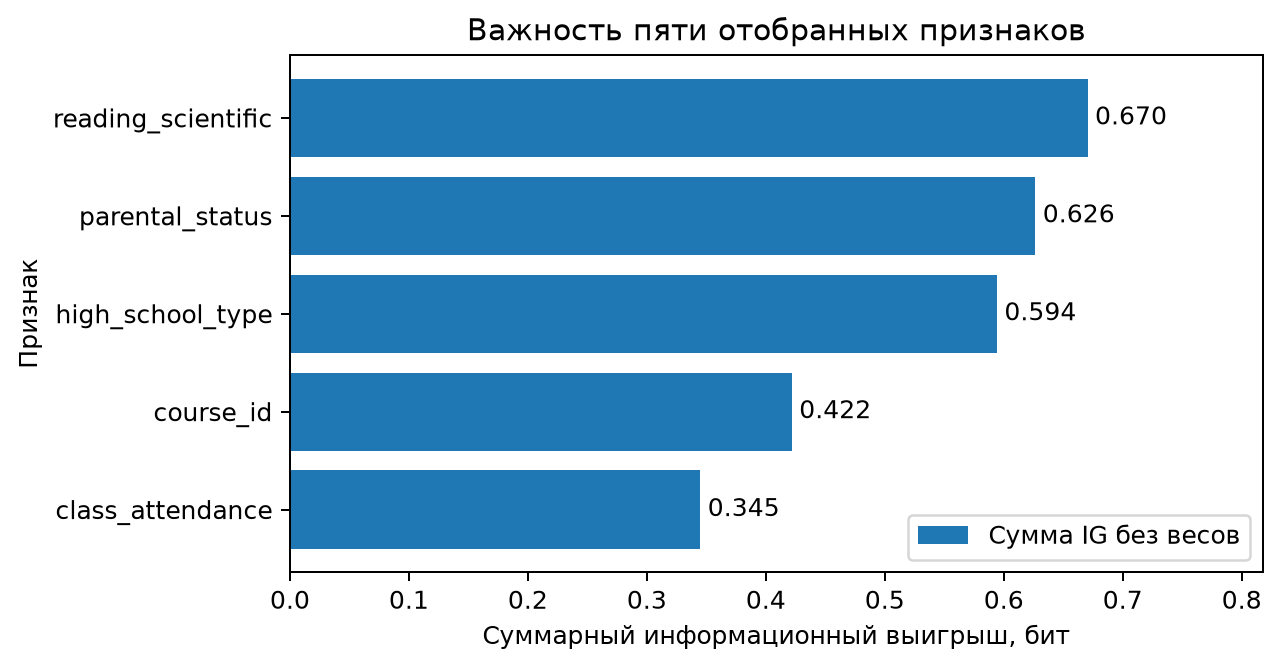

Рисунок 1. Суммарный IG по всем узлам, где использован признак.

| Признак | Сумма IG, бит |
| --- | --- |
| reading_scientific | 0.670398 |
| parental_status | 0.626482 |
| high_school_type | 0.594212 |
| course_id | 0.421771 |
| class_attendance | 0.344853 |

Наибольшая суммарная важность у reading_scientific, затем parental_status и high_school_type. Course_id выбран в корне и даёт самое сильное начальное разбиение, но его единственный IG меньше сумм повторно используемых признаков. Важность не доказывает причинной связи с успеваемостью, IG склонен отдавать предпочтение многозначным признакам.

| Выборка | Accuracy | Precision | Recall | TP | FP | FN | TN |
| --- | --- | --- | --- | --- | --- | --- | --- |
| train | 0.8362 | 0.9388 | 0.7419 | 46 | 3 | 16 | 51 |
| test | 0.7586 | 0.8462 | 0.6875 | 11 | 2 | 5 | 11 |

Основной порог 0,5. На тесте верны 22 прогноза из 29. Ложноотрицательных ошибок больше: FN = 5 против FP = 2. Пять студентов с GRADE ≥ 3 ошибочно отнесены к классу 0, два студента с GRADE < 3 — к классу 1.

## ROC И PR КРИВЫЕ

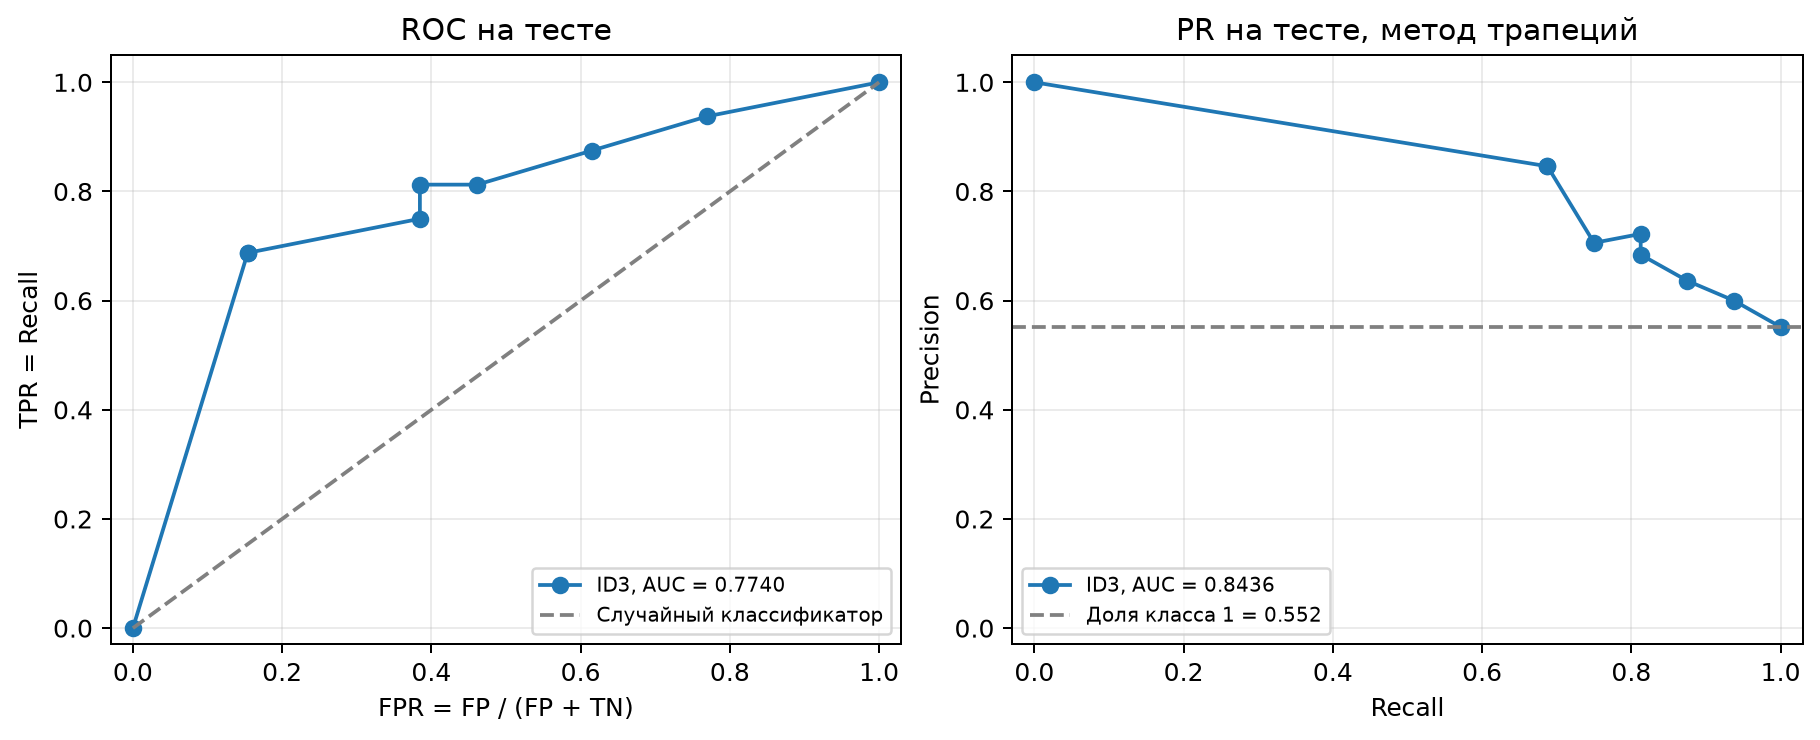

Рисунок 2. ROC и PR на тестовой выборке, площади вычислены трапециями.

ROC AUC = 0.774038, PR AUC = 0.843640. PR AUC здесь означает площадь под ломаной методом трапеций, а не average precision. Доля положительного класса в test равна 16/29 ≈ 0,5517, на PR она показана горизонтальной справочной линией.

Пороги взяты из уникальных долей класса 1 в листьях плюс 0 и 1. Код дополнительно учитывает оценки отката в текущий узел, если они встретились при предсказании. В этом тесте новых оценок не возникло. При t=0,5 и t=1 прогнозы одинаковы: в тесте нет вероятности 0,5 или между 0,5 и 1.

| Порог | TP | FP | FN | TN | Precision | Recall | FPR |
| --- | --- | --- | --- | --- | --- | --- | --- |
| +∞ | 0 | 0 | 16 | 13 | 0.0000 | 0.0000 | 0.0000 |
| 1.0000 | 11 | 2 | 5 | 11 | 0.8462 | 0.6875 | 0.1538 |
| 0.5000 | 11 | 2 | 5 | 11 | 0.8462 | 0.6875 | 0.1538 |
| 0.4706 | 12 | 5 | 4 | 8 | 0.7059 | 0.7500 | 0.3846 |
| 0.4000 | 13 | 5 | 3 | 8 | 0.7222 | 0.8125 | 0.3846 |
| 0.3333 | 13 | 6 | 3 | 7 | 0.6842 | 0.8125 | 0.4615 |
| 0.3000 | 14 | 8 | 2 | 5 | 0.6364 | 0.8750 | 0.6154 |
| 0.2500 | 15 | 10 | 1 | 3 | 0.6000 | 0.9375 | 0.7692 |
| 0.0000 | 16 | 13 | 0 | 0 | 0.5517 | 1.0000 | 1.0000 |

Технический порог +∞ добавляет точку ROC (0, 0), поскольку при правиле p ≥ t порог 1 ещё оставляет положительные прогнозы с p=1. Порог 0 даёт ROC (1, 1). Для PR при отсутствии положительных прогнозов задаётся опорная precision=1 и recall=0, в обычной таблице метрик precision остаётся 0. Эта конвенция явно отделена в столбце curve_precision файла threshold_curves.csv.

## ВЛИЯНИЕ ПОРОГА И ВЫВОДЫ

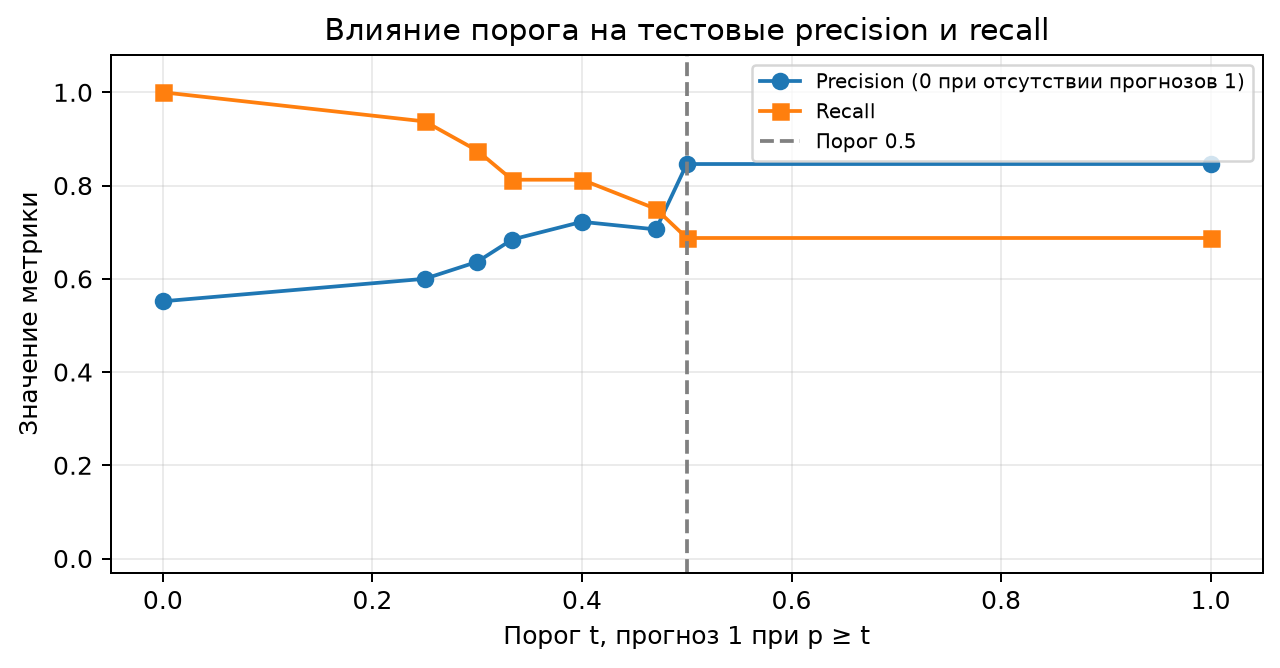

Рисунок 3. Precision и recall при изменении порога на тесте.

При снижении t с 0,5 до 0,4 recall растёт с 0,6875 до 0,8125, FN уменьшается с 5 до 3, одновременно FP увеличивается с 2 до 5, precision падает с 0,8462 до 0,7222. При t=0 все объекты положительные: FN=0, FP=13, recall=1, precision=0,5517.

При повышении порога число положительных прогнозов не растёт: TP и FP не увеличиваются, FN не уменьшается, поэтому recall не возрастает. Precision часто повышается, но строгой монотонности нет: переход от t=0,4 к t≈0,4706 уменьшает её с 0,7222 до 0,7059, так как исключается верный положительный прогноз.

Accuracy train = 0,8362, test = 0,7586: разрыв 7,76 процентного пункта. Precision падает с 0,9388 до 0,8462, recall — с 0,7419 до 0,6875. Это признаки ухудшения обобщения и возможного переобучения. Однако тест содержит лишь 29 объектов: один объект меняет accuracy на 3,45 п.п., по одному разбиению нельзя надёжно оценить устойчивость разрыва. Прунинг и дополнительная настройка в основной эксперимент не вводились.

Реализовано многоветвевое ID3 с требуемыми остановами и откатом вероятности при неизвестной категории. Главные признаки по заданной сумме IG — научное чтение, статус родителей и тип школы, самое сильное корневое разбиение даёт код курса. На тесте ложных отрицаний больше, чем ложных подтверждений. Снижение порога уменьшает пропуски класса 1 ценой увеличения FP. Итоговые метрики относятся к фиксированным пяти признакам и одному разбиению.

## РЕАЛИЗАЦИЯ ДЕРЕВА ПОСТРОЕНИЕ И ПРЕДСКАЗАНИЕ

Код двух разделов отчёта объединён в одну исполняемую ячейку,
чтобы все методы оставались внутри класса DecisionTree.

In [ ]:
"""Многоветвевое ID3: категории, энтропия и доля класса 1 в узле."""
from dataclasses import dataclass, field

import numpy as np
import pandas as pd


def entropy(y):
    p = np.bincount(np.asarray(y, dtype=int), minlength=2) / len(y)
    p = p[p > 0]  # Нулевые доли не входят в логарифм.
    return float(-np.sum(p * np.log2(p)))


@dataclass
class Node:
    probability: float
    samples: int
    feature: str | None = None
    gain: float = 0.0
    children: dict = field(default_factory=dict)


class DecisionTree:
    def fit(self, X, y):
        y = np.asarray(y)
        if (not isinstance(X, pd.DataFrame) or X.empty
                or len(X) != len(y) or y.ndim != 1
                or not np.isin(y, [0, 1]).all()
                or X.isna().any().any() or not X.columns.is_unique):
            raise ValueError("Need nonempty categorical X and matching binary y, no missing values.")
        self.features = list(X.columns)
        self.importances = dict.fromkeys(self.features, 0.0)
        self.root = self._build(X.reset_index(drop=True), y)
        return self

    def _build(self, X, y):
        node = Node(float(y.mean()), len(y))
        if node.probability in (0, 1) or X.shape[1] == 0:
            return node
        parent_entropy = entropy(y)
        for feature in X.columns:
            groups = [(value, X[feature].to_numpy() == value)
                      for value in sorted(X[feature].unique())]
            gain = parent_entropy - sum(mask.mean() * entropy(y[mask])
                                        for _, mask in groups)
            # 1e-12 устраняет погрешность нулевого выигрыша, равенство сохраняет порядок.
            if gain > node.gain + 1e-12:
                node.feature, node.gain = feature, gain
                best_groups = groups
        if node.feature is not None:
            # По заданию суммируем IG без взвешивания по размеру узла.
            self.importances[node.feature] += node.gain
            for value, mask in best_groups:
                node.children[value] = self._build(
                    X.loc[mask].drop(columns=node.feature), y[mask])
        return node

    def predict_proba(self, X):
        if not hasattr(self, "root"):
            raise ValueError("Call fit before prediction.")
        if not set(self.features).issubset(X.columns) or X[self.features].isna().any().any():
            raise ValueError("Prediction needs the fitted features and explicit missing categories.")
        probabilities = []
        for _, row in X.iterrows():
            node = self.root
            while node.feature is not None:
                child = node.children.get(row[node.feature])
                if child is None:
                    break  # Неизвестная категория: доля класса 1 в текущем узле.
                node = child
            probabilities.append(node.probability)
        return np.asarray(probabilities)

    def predict(self, X, threshold=0.5):
        if not 0 <= threshold <= 1:
            raise ValueError("Threshold must lie in [0, 1].")
        return (self.predict_proba(X) >= threshold).astype(int)

    def nodes(self):
        def visit(node, depth):
            yield node, depth
            for child in node.children.values():
                yield from visit(child, depth + 1)
        return list(visit(self.root, 0))

    def statistics(self):
        nodes = self.nodes()
        return {"depth": max(depth for _, depth in nodes),
                "leaves": sum(not node.children for node, _ in nodes),
                "nodes": len(nodes)}

    def text(self, max_depth=None):
        lines = []

        def visit(node, depth, branch):
            label = node.feature if node.feature is not None else "LEAF"
            lines.append(f"{'  ' * depth}{branch}{label}, n={node.samples}, "
                         f"p1={node.probability:.4f}, IG={node.gain:.6f}")
            if max_depth is not None and depth >= max_depth and node.children:
                lines.append(f"{'  ' * (depth + 1)}... subtree omitted")
                return
            for value, child in node.children.items():
                visit(child, depth + 1, f"[{value}] -> ")

        visit(self.root, 0, "")
        return "\n".join(lines)

## РЕАЛИЗАЦИЯ МЕТРИК И КРИВЫХ

In [ ]:
"""Собственные бинарные метрики, ROC/PR и интегрирование трапециями."""
import numpy as np
import pandas as pd


def binary_metrics(y, prediction):
    y, prediction = np.asarray(y), np.asarray(prediction)
    if (y.ndim != 1 or y.shape != prediction.shape or not y.size
            or not np.isin(y, [0, 1]).all()
            or not np.isin(prediction, [0, 1]).all()):
        raise ValueError("Need equally sized nonempty binary vectors.")
    tp = int(np.sum((y == 1) & (prediction == 1)))
    fp = int(np.sum((y == 0) & (prediction == 1)))
    fn = int(np.sum((y == 1) & (prediction == 0)))
    tn = int(np.sum((y == 0) & (prediction == 0)))
    return {"accuracy": (tp + tn) / len(y),
            "precision": tp / (tp + fp) if tp + fp else 0.0,
            "recall": tp / (tp + fn) if tp + fn else 0.0,
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}


def trapezoid_auc(x, y):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    if (x.ndim != 1 or x.shape != y.shape or len(x) < 2
            or not np.isfinite(x).all() or not np.isfinite(y).all()):
        raise ValueError("Need matching finite curve coordinates with at least two points.")
    # Стабильность сохраняет порядок порогов при одинаковых x.
    order = np.argsort(x, kind="stable")
    x, y = x[order], y[order]
    return float(np.sum((x[1:] - x[:-1]) * (y[1:] + y[:-1]) / 2))


def classification_curves(y, scores, leaf_probabilities=()):
    y, scores = np.asarray(y), np.asarray(scores, dtype=float)
    if (y.ndim != 1 or y.shape != scores.shape or set(y) != {0, 1}
            or not np.isfinite(scores).all() or np.any((scores < 0) | (scores > 1))):
        raise ValueError("Curves need both classes and finite scores in [0, 1].")
    # Кроме листьев учитываем оценки отката при неизвестной категории.
    thresholds = sorted(set(scores) | set(leaf_probabilities) | {0.0, 1.0}, reverse=True)
    rows = []
    # +inf даёт опорную точку без положительных прогнозов даже при score=1.
    for threshold in [np.inf] + thresholds:
        m = binary_metrics(y, scores >= threshold)
        rows.append({"threshold": threshold, **m,
                     "FPR": m["FP"] / (m["FP"] + m["TN"]),
                     "TPR": m["recall"],
                     "curve_precision": m["precision"] if m["TP"] + m["FP"] else 1.0})
    points = pd.DataFrame(rows)
    areas = {"ROC_AUC": trapezoid_auc(points.FPR, points.TPR),
             "PR_AUC": trapezoid_auc(points.recall, points.curve_precision)}
    return points, areas

: 

## Пошаговое воспроизведение 

Повторяется протокол отчёта. Признаки выбираются один раз.
Тестовая выборка не используется для обучения или выбора лучшего порога.

In [ ]:
import hashlib
import json
from sklearn.model_selection import train_test_split

SEED = 42
FEATURES = [
    "student_age", "sex", "high_school_type", "scholarship_type",
    "additional_work", "artistic_sports_activity", "partner", "salary",
    "transportation", "accommodation", "mother_education", "father_education",
    "siblings", "parental_status", "mother_occupation", "father_occupation",
    "weekly_study_hours", "reading_non_scientific", "reading_scientific",
    "seminar_attendance", "project_impact", "class_attendance",
    "exam_preparation_company", "exam_preparation_time", "taking_notes",
    "listening", "discussion", "flipped_classroom", "previous_gpa",
    "expected_gpa", "course_id",
]

def prepare_data(path):
    raw = pd.read_csv(path, dtype=str)
    expected = ["STUDENT ID"] + [str(i) for i in range(1, 31)] + ["COURSE ID", "GRADE"]
    if list(raw.columns) != expected or raw.empty:
        raise ValueError("Unexpected UCI 856 schema or empty data.")
    grade = pd.to_numeric(raw["GRADE"], errors="raise")
    if grade.isna().any() or not grade.isin(range(8)).all():
        raise ValueError("GRADE must contain integer categories 0..7.")
    X = raw.drop(columns=["STUDENT ID", "GRADE"]).copy()
    X.columns = FEATURES
    X = X.apply(lambda col: col.str.strip()).replace({"": pd.NA, "?": pd.NA})
    missing = X.isna().sum()
    X = X.fillna("<MISSING>")  # Пропуск становится обычной отдельной категорией.
    return raw, X, (grade >= 3).astype(int).to_numpy(), missing

### Подготовка данных и разбиение

In [ ]:
from experiment import ROOT

path = ROOT / "data" / "students.csv"
assert hashlib.sha256(path.read_bytes()).hexdigest() == "d5905d231bedd7e4cdcf708fab55fc65b79dfe12012e846eccad3e88b5ecb019"
raw, X_all, y, missing = prepare_data(path)
selected = np.random.default_rng(SEED).choice(X_all.columns, int(np.sqrt(X_all.shape[1])), replace=False).tolist()
X = X_all[selected]
train, test = train_test_split(np.arange(len(y)), test_size=0.2, random_state=SEED, stratify=y)
counts = {name:{str(c):int(np.sum(y[indices]==c)) for c in (0,1)}
          for name,indices in (("all",np.arange(len(y))),("train",train),("test",test))}
print("Objects:",len(y),"Candidate features:",X_all.shape[1])
print("Selected:",selected)
print("Missing:",int(missing.sum()),"Duplicate rows:",int(raw.duplicated().sum()))
print(pd.DataFrame(counts).T.to_string())
print(X.head().to_string(index=False))

Objects: 145 Candidate features: 31
Selected: ['class_attendance', 'parental_status', 'reading_scientific', 'high_school_type', 'course_id']
Missing: 0 Duplicate rows: 0
        0   1
all    67  78
train  54  62
test   13  16
class_attendance parental_status reading_scientific high_school_type course_id
               1               1                  2                3         1
               1               1                  2                3         1
               1               1                  2                2         1
               1               1                  2                1         1
               1               1                  1                1         1


### Обучение и структура дерева

In [ ]:
model = DecisionTree().fit(X.iloc[train],y[train])
print(model.statistics())
print(model.text(max_depth=3))
mixed = [node for node,_ in model.nodes() if not node.children and 0 < node.probability < 1]
print("Mixed leaves:",len(mixed),"Samples:",sum(n.samples for n in mixed))

{'depth': 5, 'leaves': 31, 'nodes': 48}
course_id, n=116, p1=0.5345, IG=0.421771
  [1] -> high_school_type, n=53, p1=0.3774, IG=0.051683
    [1] -> reading_scientific, n=9, p1=0.1111, IG=0.102187
      [1] -> LEAF, n=3, p1=0.0000, IG=0.000000
      [2] -> class_attendance, n=5, p1=0.2000, IG=0.072906
        ... subtree omitted
      [3] -> LEAF, n=1, p1=0.0000, IG=0.000000
    [2] -> parental_status, n=37, p1=0.4324, IG=0.049608
      [1] -> class_attendance, n=33, p1=0.3939, IG=0.036962
        ... subtree omitted
      [2] -> reading_scientific, n=3, p1=0.6667, IG=0.251629
        ... subtree omitted
      [3] -> LEAF, n=1, p1=1.0000, IG=0.000000
    [3] -> parental_status, n=7, p1=0.4286, IG=0.128085
      [1] -> class_attendance, n=6, p1=0.5000, IG=0.190875
        ... subtree omitted
      [2] -> LEAF, n=1, p1=0.0000, IG=0.000000
  [2] -> LEAF, n=1, p1=0.0000, IG=0.000000
  [3] -> LEAF, n=7, p1=1.0000, IG=0.000000
  [4] -> LEAF, n=4, p1=1.0000, IG=0.000000
  [5] -> LEAF, n=5, p1=

### Важность признаков и метрики при пороге 0.5

In [ ]:
importance = pd.DataFrame({"feature":selected,"sum_IG":[model.importances[f] for f in selected]})
importance = importance.sort_values("sum_IG",ascending=False,kind="stable")
rows = []
scores_by_split = {}
for name,indices in (("train",train),("test",test)):
    scores = model.predict_proba(X.iloc[indices])
    scores_by_split[name] = scores
    rows.append({"split":name,**binary_metrics(y[indices],scores >= 0.5)})
metrics = pd.DataFrame(rows)
print(importance.to_string(index=False,float_format=lambda x:f"{x:.6f}"))
print(metrics.to_string(index=False,float_format=lambda x:f"{x:.4f}"))

           feature   sum_IG
reading_scientific 0.670398
   parental_status 0.626482
  high_school_type 0.594212
         course_id 0.421771
  class_attendance 0.344853
split  accuracy  precision  recall  TP  FP  FN  TN
train    0.8362     0.9388  0.7419  46   3  16  51
 test    0.7586     0.8462  0.6875  11   2   5  11


### ROC и PR и влияние порога

In [ ]:
leaf_probs = [node.probability for node,_ in model.nodes() if not node.children]
curve,areas = classification_curves(y[test],scores_by_split["test"],leaf_probs)
print(json.dumps(areas,indent=2))
print(curve.to_string(index=False,float_format=lambda x:f"{x:.6f}"))

{
  "ROC_AUC": 0.7740384615384615,
  "PR_AUC": 0.8436404693414008
}
 threshold  accuracy  precision   recall  TP  FP  FN  TN      FPR      TPR  curve_precision
       inf  0.448276   0.000000 0.000000   0   0  16  13 0.000000 0.000000         1.000000
  1.000000  0.758621   0.846154 0.687500  11   2   5  11 0.153846 0.687500         0.846154
  0.500000  0.758621   0.846154 0.687500  11   2   5  11 0.153846 0.687500         0.846154
  0.470588  0.689655   0.705882 0.750000  12   5   4   8 0.384615 0.750000         0.705882
  0.400000  0.724138   0.722222 0.812500  13   5   3   8 0.384615 0.812500         0.722222
  0.333333  0.689655   0.684211 0.812500  13   6   3   7 0.461538 0.812500         0.684211
  0.300000  0.655172   0.636364 0.875000  14   8   2   5 0.615385 0.875000         0.636364
  0.250000  0.620690   0.600000 0.937500  15  10   1   3 0.769231 0.937500         0.600000
  0.000000  0.551724   0.551724 1.000000  16  13   0   0 1.000000 1.000000         0.551724


### Графики

Расчёт соответствует graphics.py, графики выводятся в Notebook без записи в output.

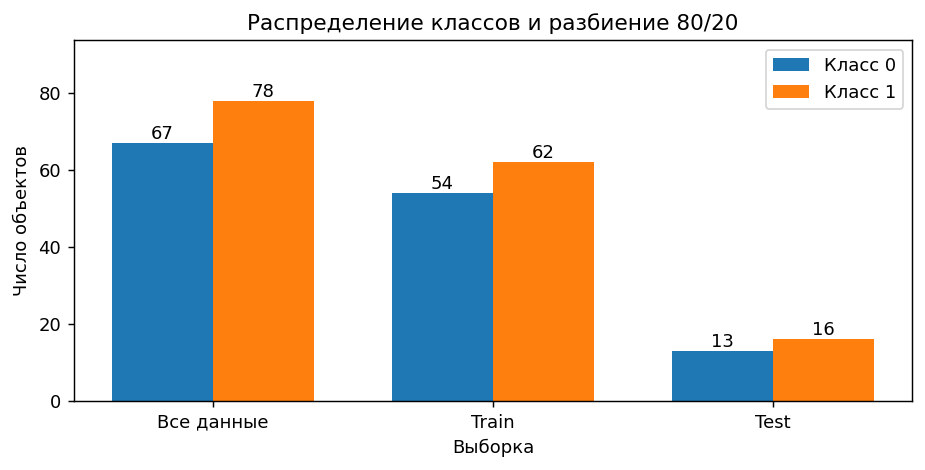

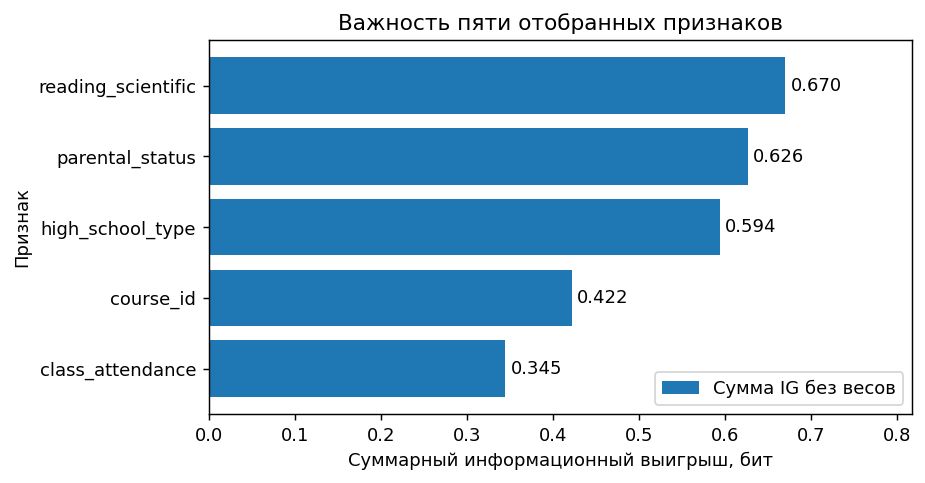

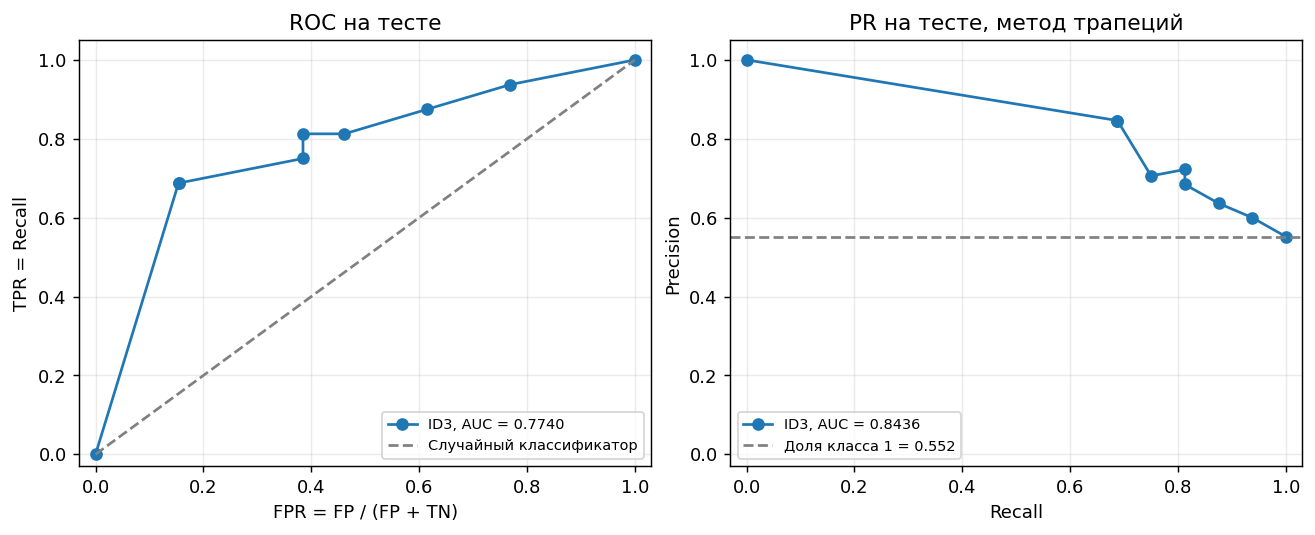

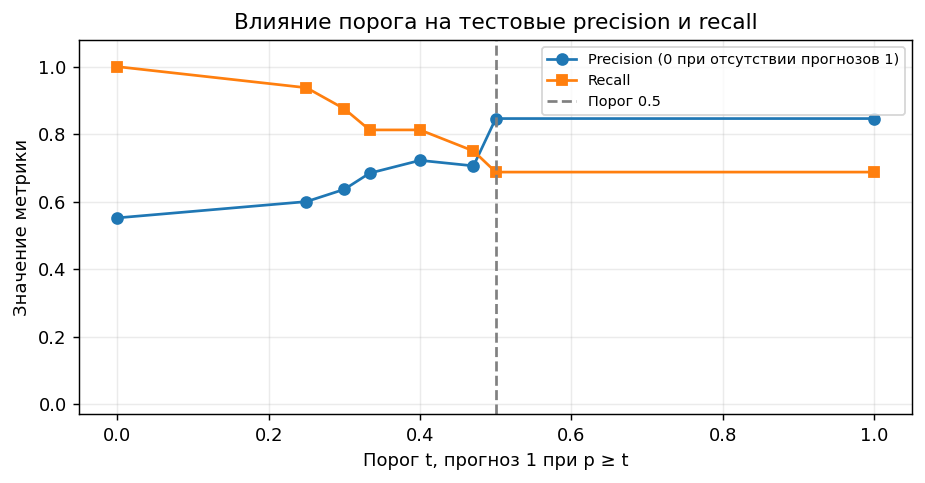

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def plot_results(counts, importance, curve, areas):
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})

    def save(fig, name):
        plt.show()
        plt.close(fig)

    fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
    x = np.arange(3)
    for c, offset in ((0, -0.18), (1, 0.18)):
        bars = ax.bar(x + offset, [counts[s][str(c)] for s in ("all", "train", "test")],
                      0.36, label=f"Класс {c}")
        ax.bar_label(bars)
    ax.set(xticks=x, xticklabels=["Все данные", "Train", "Test"], xlabel="Выборка",
           ylabel="Число объектов", title="Распределение классов и разбиение 80/20")
    ax.set_ylim(0, max(counts["all"].values()) * 1.2)
    ax.legend()
    save(fig, "class_counts")

    fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
    bars = ax.barh(importance.feature, importance.sum_IG, label="Сумма IG без весов")
    ax.invert_yaxis()
    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set(xlabel="Суммарный информационный выигрыш, бит", ylabel="Признак",
           title="Важность пяти отобранных признаков")
    ax.set_xlim(0, importance.sum_IG.max() * 1.22)
    ax.legend(loc="lower right")
    save(fig, "feature_importance")

    fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
    axes[0].plot(curve.FPR, curve.TPR, "o-", label=f"ID3, AUC = {areas['ROC_AUC']:.4f}")
    axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Случайный классификатор")
    axes[0].set(xlabel="FPR = FP / (FP + TN)", ylabel="TPR = Recall", title="ROC на тесте")
    axes[1].plot(curve.recall, curve.curve_precision, "o-", label=f"ID3, AUC = {areas['PR_AUC']:.4f}")
    prevalence = counts["test"]["1"] / sum(counts["test"].values())
    axes[1].axhline(prevalence, linestyle="--", color="gray", label=f"Доля класса 1 = {prevalence:.3f}")
    axes[1].set(xlabel="Recall", ylabel="Precision", title="PR на тесте, метод трапеций")
    for ax in axes:
        ax.set(xlim=(-0.03, 1.03), ylim=(-0.03, 1.05))
        ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "lower left")
        ax.grid(alpha=0.25)
    save(fig, "roc_pr")

    finite = curve[np.isfinite(curve.threshold)].sort_values("threshold")
    fig, ax = plt.subplots(figsize=(7, 3.6), layout="constrained")
    ax.plot(finite.threshold, finite.precision, "o-", label="Precision (0 при отсутствии прогнозов 1)")
    ax.plot(finite.threshold, finite.recall, "s-", label="Recall")
    ax.axvline(0.5, linestyle="--", color="gray", label="Порог 0.5")
    ax.set(xlabel="Порог t, прогноз 1 при p ≥ t", ylabel="Значение метрики",
           title="Влияние порога на тестовые precision и recall", ylim=(-0.03, 1.08))
    ax.legend(fontsize=8)
    ax.grid(alpha=0.25)
    save(fig, "threshold_effect")


plot_results(counts, importance, curve, areas)

### Проверка соответствия отчёту 

In [1]:
expected = {'seed': 42, 'variant': 'odd', 'source': 'https://archive.ics.uci.edu/dataset/856', 'dataset_sha256': 'd5905d231bedd7e4cdcf708fab55fc65b79dfe12012e846eccad3e88b5ecb019', 'objects': 145, 'candidate_features': 31, 'selected_features': ['class_attendance', 'parental_status', 'reading_scientific', 'high_school_type', 'course_id'], 'missing_values': 0, 'raw_duplicate_rows': 0, 'class_counts': {'all': {'0': 67, '1': 78}, 'train': {'0': 54, '1': 62}, 'test': {'0': 13, '1': 16}}, 'tree': {'depth': 5, 'leaves': 31, 'nodes': 48}, 'metrics': [{'split': 'train', 'accuracy': 0.8362068965517241, 'precision': 0.9387755102040817, 'recall': 0.7419354838709677, 'TP': 46, 'FP': 3, 'FN': 16, 'TN': 51}, {'split': 'test', 'accuracy': 0.7586206896551724, 'precision': 0.8461538461538461, 'recall': 0.6875, 'TP': 11, 'FP': 2, 'FN': 5, 'TN': 11}], 'test_auc': {'ROC_AUC': 0.7740384615384615, 'PR_AUC': 0.8436404693414008}, 'leaf_probabilities': [0.0, 0.25, 0.3, 0.3333333333333333, 0.4, 0.47058823529411764, 0.5, 1.0], 'node_features': ['class_attendance', 'course_id', 'high_school_type', 'parental_status', 'reading_scientific'], 'threshold_rule': 'score >= threshold', 'importance_rule': 'unweighted sum of node IG'}
assert selected == expected["selected_features"]
assert model.statistics() == expected["tree"]
assert counts == expected["class_counts"]
for actual,reference in zip(rows,expected["metrics"]):
    assert actual["split"] == reference["split"]
    for key in ("accuracy","precision","recall","TP","FP","FN","TN"):
        assert np.isclose(actual[key],reference[key],rtol=0,atol=1e-12),key
for key,value in expected["test_auc"].items():
    assert np.isclose(areas[key],value,rtol=0,atol=1e-12),key
assert len(mixed)==9 and sum(n.samples for n in mixed)==49
assert model.root.feature=="course_id"
assert np.isclose(entropy([0,1]),1.0)
assert np.isclose(entropy([1,1]),0.0)
unknown = X.iloc[[0]].copy()
unknown.loc[:,"course_id"] = "UNSEEN_CATEGORY"
assert np.isclose(model.predict_proba(unknown)[0],model.root.probability)
assert np.isclose(trapezoid_auc([1,0],[1,0]),0.5)
baseline = binary_metrics(y[test],scores_by_split["test"] >= 0.5)
lower = binary_metrics(y[test],scores_by_split["test"] >= 0.4)
assert (baseline["TP"],baseline["FP"],baseline["FN"])==(11,2,5)
assert (lower["TP"],lower["FP"],lower["FN"])==(13,5,3)
print("All checks passed, results match the completed report")

NameError: name 'selected' is not defined